## Quiz 3. Identificación No Parmétrica

## Esteban Garcia Otalvaro


## CC.1001446658

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy.signal as signal

In [3]:
df = pd.read_csv('set3.csv')

print(df.shape)
df.head()

(750, 5)


,t,u,y,uv,yv
0,0.00,0.000000,0.000000,0.000000,0.000000
1,0.02,0.091960,0.000024,0.013581,0.000004
2,0.04,0.182270,0.000193,0.027177,0.000029
3,0.06,0.269337,0.000646,0.040787,0.000096
4,0.08,0.351685,0.001511,0.054406,0.000226


In [43]:
t = df.t
u = df.u
y = df.y
uv = df.uv
yv = df.yv
N = len(y)               # Número de datos
print(N)
p = round(0.6*N)
Ts = np.mean(np.diff(t)) # Periodo de muestréo

750


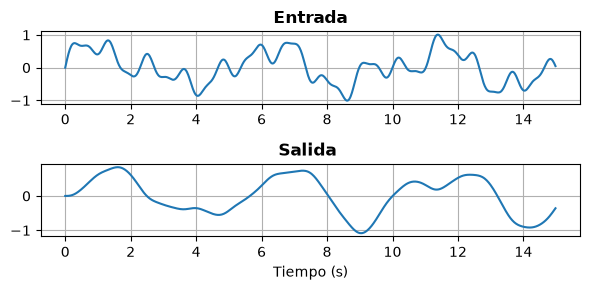

In [46]:
plt.figure(figsize=(6,3))

plt.subplot(2,1,1)
plt.plot(t,u)
plt.grid(True)
plt.title('Entrada',fontweight='bold')

plt.subplot(2,1,2)
plt.plot(t,y)
plt.grid(True)
plt.title('Salida ',fontweight='bold')
plt.xlabel('Tiempo (s)')

plt.tight_layout()
plt.show()

## Identificar por desconvolucion

In [55]:
ypad = np.concatenate([y, np.zeros(round(p))])

h_desc, residuo = signal.deconvolve(ypad, u)
y_desc = np.convolve(h_desc, u)




ValueError: BUG: filter coefficient a[0] == 0 not supported yet

In [51]:
def minimo_error_cuadratico(T, u, y, p, N):
  UU = np.zeros((N, p))

  # Se llena la matriz sobre sus columnas
  for i in range(p):
    if i == 0:
      UU[:,0] = u

    else:
      UU[i:, i] = u[:N-i]

  # Se calcula la formula
  UU *= T
  AA = UU.T @ UU                  # (U'U)
  b = UU.T @ y                    # U'y
  h = np.linalg.solve(AA, b) * T  # [(U'U)^(-1)U'y] * T

  return h

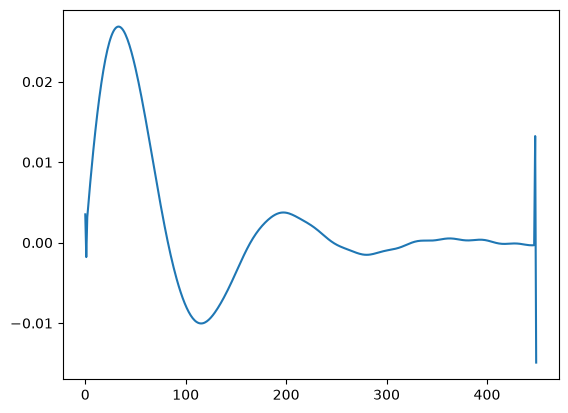

In [56]:
h_lce = minimo_error_cuadratico(Ts, u, y, p, N)

y_lce = np.convolve(h_lce, u)

plt.figure()
plt.plot(h_lce)
plt.show()

NameError: name 'y_desc' is not defined

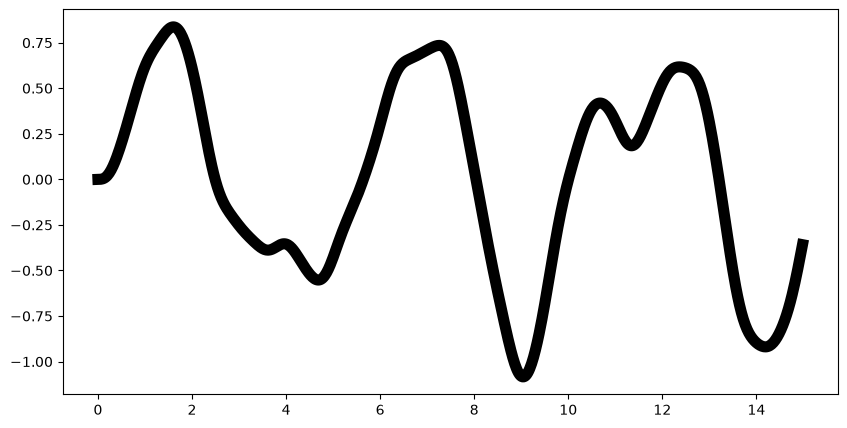

In [57]:
plt.figure(figsize=(10,5))
plt.plot(t, y, color='black', linewidth=8, label='Real')
plt.plot(t, y_desc[0:len(t)], color='red', linewidth=4, label='Predicha por desconvolución')
plt.plot(t, y_lce[0:len(t)], color='blue', linewidth=2, label='Predicha por mínimo error cuadrático')

plt.xlim(0, np.max(t))
plt.grid()
plt.legend()
plt.xlabel('Tiempo')
plt.ylabel('Valores de salida')
plt.title("Predicciones por desconvolución y mínimo error cuadrático para los datos de 'y' y 'u'")

plt.tight_layout()
plt.show()

# Predicción para 'yv' y 'vu'

In [60]:
yv_desc = np.convolve(h_desc, uv)

NameError: name 'h_desc' is not defined

In [58]:
yv_lce = np.convolve(h_lce, uv)

NameError: name 'yv_desc' is not defined

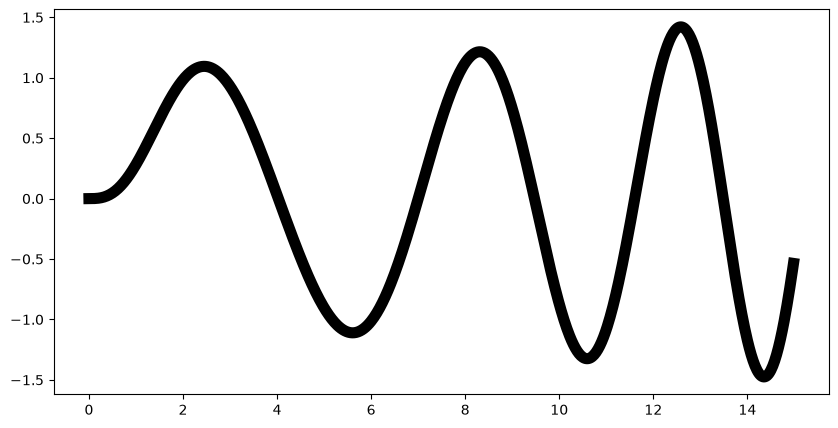

In [61]:
plt.figure(figsize=(10,5))
plt.plot(t, yv, color='black', linewidth=8, label='Real')
plt.plot(t, yv_desc[0:len(t)], color='red', linewidth=4, label='Predicha por desconvolución')
plt.plot(t, yv_lce[0:len(t)], color='blue', linewidth=2, label='Predicha por mínimo error cuadrático')

plt.xlim(0, np.max(t))
plt.grid()
plt.legend()
plt.xlabel('Tiempo')
plt.ylabel('Valores de salida')
plt.title("Predicciones por desconvolución y mínimo error cuadrático para los datos de 'yv' y 'vu'")

plt.tight_layout()
plt.show()